# Phase 1 – Part B: Supervised Learning
## Model 1: Random Forest
**Member 5:** Joud Alkahtani

## 1. Model Selection Rationale – Random Forest

### 1.1 Dataset characteristics
- **Size:** 24,000 training rows and 29 features after preprocessing. This is large enough for an ensemble of many trees without severe overfitting.
- **Feature types:** The data mixes one-hot encoded categories (EDUCATION), ordered repayment codes (PAY_0 to PAY_6), engineered features (MONTHS_LATE, UTILIZATION) and monetary amounts. Decision trees handle all of these types directly.
- **Non-linearity:** The EDA showed that the default rate jumps from 12.8% (PAY_0 = 0) to 69.4% (PAY_0 = 2). Trees capture threshold effects like this naturally, while a linear model would need extra feature engineering.
- **Outliers and skewness:** Monetary features are highly skewed. Tree splits depend only on the order of values, not their size, so extreme values have limited influence.
- **Correlated features:** BILL_AMT1 to BILL_AMT6 are strongly correlated (0.80 to 0.95). This does not hurt Random Forest accuracy, but it spreads importance across the correlated features.

### 1.2 Problem type
This is a **binary classification** problem (0 = no default, 1 = default) with **class imbalance** (22.12% defaults). Random Forest supports `class_weight` to give the minority class more weight, and it outputs probabilities, which we need for ROC-AUC and for adjusting the decision threshold.

### 1.3 Strengths and weaknesses for this problem
| Strengths | Weaknesses |
|---|---|
| Less overfitting than a single tree (bagging + random feature selection) | Harder to interpret than a single decision tree |
| Provides feature importance that executives can understand | Built-in importance is biased toward features with many unique values |
| No scaling needed; robust to outliers | Larger model and slower predictions than linear models |
| Handles correlated and mixed-type features | Predicted probabilities are not always well calibrated |

**Note on preprocessing:** Random Forest does not need scaling. We still use the shared preprocessed dataset so that Random Forest and SVM are trained and tested on exactly the same data. Scaling and log transforms keep the order of values, so they do not change how the trees split.

**Why compare it with SVM:** Random Forest splits the data along one feature at a time, while SVM looks for a separating boundary with the largest margin. Comparing these two different approaches shows which one suits our data better.

In [1]:
# ===== Imports and settings =====
import time
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.metrics import (classification_report, accuracy_score,
                             precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

# The dummy model never predicts "Default", so precision is undefined (0/0).
# We hide that expected warning to keep the output clean.
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

RANDOM_STATE = 42                      # same value used by the whole team
TARGET = "default.payment.next.month"  # target column

# Find the project folder (works from the repo root or from Supervised_Learning/)
ROOT = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent

# Output folders required by the project handbook
MODELS_DIR = ROOT / "Supervised_Learning" / "models"
RESULTS_DIR = ROOT / "Supervised_Learning" / "evaluation_results"
PLOTS_DIR = ROOT / "Supervised_Learning" / "plots"
for folder in [MODELS_DIR, RESULTS_DIR, PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)

Project root: /content


In [2]:
# ===== Load the preprocessed data (prepared in Phase1_Data_Exploration) =====
data = pd.read_csv(ROOT / "Dataset" / "preprocessed_data.csv")

# The file already contains the team's train/test split in the "split" column
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

# ID is only for linking rows back to the raw data; it is not a model input
drop_cols = ["ID", TARGET, "split"]

X_train = train.drop(columns=drop_cols)
y_train = train[TARGET]
X_test = test.drop(columns=drop_cols)
y_test = test[TARGET]
test_ids = test["ID"]  # kept for the misclassification analysis later

print("Training set:", X_train.shape, "| defaults:", y_train.sum())
print("Test set:    ", X_test.shape, "| defaults:", y_test.sum())

# Safety check: stop if the split is different from the team's split
assert X_train.shape == (24000, 29) and X_test.shape == (6000, 29)
assert y_train.sum() == 5309 and y_test.sum() == 1327
print("Split verified: identical to the team's split.")

Training set: (24000, 29) | defaults: 5309
Test set:     (6000, 29) | defaults: 1327
Split verified: identical to the team's split.


## 2. Data Loading

We load `preprocessed_data.csv`, which was produced by the preprocessing pipeline in `Phase1_Data_Exploration.ipynb`. The file stores both sets with a `split` column, so Random Forest and SVM use **exactly the same** training and test rows. The `assert` statements confirm the expected shapes: 24,000 training rows, 6,000 test rows and 29 features.

The test set is kept aside and is used **only once**, in the final evaluation. All tuning and model decisions are made on the training set to avoid data leakage.

In [3]:
# ===== Cross-validation setup (shared with the SVM model) =====
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",   # for the Default class (1)
    "recall": "recall",         # for the Default class (1)
    "f1": "f1",                 # for the Default class (1)
    "roc_auc": "roc_auc",
}

def summarize_cv(results, model_name):
    """Turn cross_validate output into a readable table."""
    rows = []
    for metric in scoring:
        rows.append({
            "Model": model_name,
            "Metric": metric,
            "Train (mean)": results[f"train_{metric}"].mean(),
            "Validation (mean)": results[f"test_{metric}"].mean(),
            "Validation (std)": results[f"test_{metric}"].std(),
        })
    return pd.DataFrame(rows)

# Reference 1: a "model" that always predicts the majority class (No Default)
dummy = DummyClassifier(strategy="most_frequent")
dummy_results = cross_validate(dummy, X_train, y_train, cv=cv,
                               scoring=scoring, return_train_score=True)

# Reference 2: Random Forest with default settings
baseline_rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
baseline_results = cross_validate(baseline_rf, X_train, y_train, cv=cv,
                                  scoring=scoring, return_train_score=True)

baseline_table = pd.concat([
    summarize_cv(dummy_results, "Dummy (always No Default)"),
    summarize_cv(baseline_results, "RF (default settings)"),
])
baseline_table.round(3)

,Model,Metric,Train (mean),Validation (mean),Validation (std)
0,Dummy (always No Default),accuracy,0.779,0.779,0.000
1,Dummy (always No Default),precision,0.000,0.000,0.000
2,Dummy (always No Default),recall,0.000,0.000,0.000
3,Dummy (always No Default),f1,0.000,0.000,0.000
4,Dummy (always No Default),roc_auc,0.500,0.500,0.000
0,RF (default settings),accuracy,0.999,0.816,0.004
1,RF (default settings),precision,0.998,0.645,0.013
2,RF (default settings),recall,0.997,0.377,0.012
3,RF (default settings),f1,0.998,0.475,0.013
4,RF (default settings),roc_auc,1.000,0.765,0.004


## 3. Baseline Models

Before tuning, we train two reference models using 5-fold stratified cross-validation on the training set:

- **Dummy classifier:** always predicts "No Default". It reaches about 77.9% accuracy but an F1-score of 0 for the Default class, because it never detects a single defaulter. This proves that **accuracy alone is misleading** for our imbalanced data.
- **Random Forest with default settings:** it scores 0.998 on the training folds but only 0.475 F1 on the validation folds. This large gap shows **overfitting**: with no depth limit, the trees memorize the training data. Its recall for the Default class is only 0.377, so it misses most defaulters.

These results give us a reference point to measure the effect of hyperparameter tuning.

In [4]:
# ===== Hyperparameter tuning with RandomizedSearchCV =====
param_distributions = {
    "n_estimators": [100, 200, 300],            # number of trees
    "max_depth": [None, 8, 12, 16, 20],         # maximum depth of each tree
    "min_samples_split": [2, 5, 10, 20],        # min samples to split a node
    "min_samples_leaf": [1, 2, 4, 8],           # min samples in a leaf
    "max_features": ["sqrt", "log2", 0.5],      # features tried at each split
    "class_weight": [None, "balanced", "balanced_subsample"],  # imbalance handling
}

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=20,              # 20 random combinations x 5 folds = 100 fits
    scoring=scoring,
    refit="f1",             # choose the best model by F1 of the Default class
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)

start = time.perf_counter()
search.fit(X_train, y_train)   # training set only (no test data used here)
search_minutes = (time.perf_counter() - start) / 60

print(f"Search time: {search_minutes:.1f} minutes")
print("Best parameters:", search.best_params_)
print(f"Best cross-validated F1 (Default class): {search.best_score_:.3f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Search time: 29.2 minutes
Best parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 'log2', 'max_depth': 12, 'class_weight': 'balanced'}
Best cross-validated F1 (Default class): 0.544


In [5]:
# ===== Top 5 parameter combinations =====
cv_df = pd.DataFrame(search.cv_results_)
top5 = (cv_df.sort_values("rank_test_f1")
        [["rank_test_f1", "params", "mean_test_f1", "mean_test_recall",
          "mean_test_precision", "mean_test_roc_auc", "mean_train_f1"]]
        .head(5))

# Save the best parameters for documentation
with open(RESULTS_DIR / "rf_best_params.json", "w") as f:
    json.dump(search.best_params_, f, indent=2)

top5.round(3)

,rank_test_f1,params,mean_test_f1,mean_test_recall,mean_test_precision,mean_test_roc_auc,mean_train_f1
3,1,"{'n_estimators': 100, 'min_samples_split': 5, ...",0.544,0.580,0.512,0.784,0.646
4,2,"{'n_estimators': 100, 'min_samples_split': 10,...",0.544,0.608,0.492,0.783,0.589
6,3,"{'n_estimators': 300, 'min_samples_split': 2, ...",0.544,0.566,0.523,0.785,0.697
8,4,"{'n_estimators': 100, 'min_samples_split': 10,...",0.543,0.556,0.531,0.782,0.739
11,5,"{'n_estimators': 300, 'min_samples_split': 5, ...",0.543,0.595,0.499,0.784,0.611


## 4. Hyperparameter Tuning

**Method:** We used `RandomizedSearchCV`, which tests 20 random combinations from the search space with 5-fold stratified cross-validation (100 model fits). Randomized search covers a wide space faster than grid search, which would need to test all 2,160 combinations.

**Search space and purpose of each parameter:**

| Parameter | Values tested | What it controls |
|---|---|---|
| n_estimators | 100, 200, 300 | Number of trees; more trees give more stable predictions but take longer |
| max_depth | None, 8, 12, 16, 20 | Maximum tree depth; the main control against overfitting |
| min_samples_split | 2, 5, 10, 20 | Minimum samples needed to split a node |
| min_samples_leaf | 1, 2, 4, 8 | Minimum samples in a leaf; larger values give smoother decisions |
| max_features | sqrt, log2, 0.5 | Features considered at each split; adds diversity between trees |
| class_weight | None, balanced, balanced_subsample | Gives the minority (Default) class more weight |

**Selection metric:** We selected the model with the highest **F1-score for the Default class**. F1 balances recall (catching defaulters) and precision (not wrongly flagging good clients). Accuracy was not used because the dummy model already reaches about 78%.

**Best parameters:** {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 'log2', 'max_depth': 12, 'class_weight': 'balanced'}

**Interpretation:**

- **`max_depth=12` and `min_samples_leaf=8`:** The default model had no depth limit and allowed leaves with a single client, which caused severe overfitting (0.998 F1 on training vs 0.475 on validation). Limiting the depth and requiring at least 8 clients per leaf forces each decision to be based on a group of similar clients instead of memorizing individuals.
- **`class_weight="balanced"`:** Each defaulter receives about 3.5 times the weight of a non-defaulter, which matches the class ratio in the training set. This pushes the model to detect more defaulters: validation recall increased from 0.377 to 0.580.
- **`n_estimators=100`:** The smallest number of trees in the search was selected, which means adding more trees did not improve F1. This keeps the model faster and smaller.

The top 5 combinations all reach an F1-score between 0.543 and 0.544. This shows that performance is stable across several reasonable settings, so the model is not overly sensitive to the exact choice of hyperparameters.

In [6]:
# ===== 5-fold cross-validation of the tuned model =====
best_rf = search.best_estimator_

final_results = cross_validate(best_rf, X_train, y_train, cv=cv,
                               scoring=scoring, return_train_score=True)
final_table = summarize_cv(final_results, "RF (tuned)")
final_table.to_csv(RESULTS_DIR / "rf_cv_results.csv", index=False)

# Baseline vs tuned (validation scores)
comparison = pd.concat([summarize_cv(baseline_results, "RF (default settings)"),
                        final_table])
display(comparison.pivot(index="Metric", columns="Model",
                         values="Validation (mean)").round(3))

final_table.round(3)

Model,RF (default settings),RF (tuned)
Metric,,
accuracy,0.816,0.785
f1,0.475,0.544
precision,0.645,0.512
recall,0.377,0.580
roc_auc,0.765,0.784


,Model,Metric,Train (mean),Validation (mean),Validation (std)
0,RF (tuned),accuracy,0.831,0.785,0.003
1,RF (tuned),precision,0.601,0.512,0.007
2,RF (tuned),recall,0.698,0.580,0.006
3,RF (tuned),f1,0.646,0.544,0.004
4,RF (tuned),roc_auc,0.894,0.784,0.006


## 5. Cross-Validation Results (Tuned Model)

The tuned model was evaluated with 5-fold stratified cross-validation on the training set.

**Baseline vs tuned:** F1 for the Default class improved from 0.475 to 0.544, and recall improved from 0.377 to 0.580. Precision decreased from 0.645 to 0.512, and accuracy decreased slightly from 0.816 to 0.785. This is expected: the model now flags more clients as risky, so it catches more defaulters but also makes more false alarms. For a bank, missing a defaulter is usually more costly than reviewing a good client.

**Stability:** The standard deviation across the 5 folds is small (between 0.003 and 0.007 for all metrics), so performance is stable and does not depend on one lucky split.

**Overfitting:** The gap between training and validation F1 dropped from 0.523 (default model: 0.998 vs 0.475) to 0.102 (tuned model: 0.646 vs 0.544), which confirms that tuning reduced overfitting.

In [7]:
# ===== Final evaluation on the test set (used only once) =====
start = time.perf_counter()
best_rf.fit(X_train, y_train)
train_seconds = time.perf_counter() - start

y_pred = best_rf.predict(X_test)               # predicted class (threshold 0.5)
y_proba = best_rf.predict_proba(X_test)[:, 1]  # probability of Default

print(classification_report(y_test, y_pred,
                            target_names=["No Default (0)", "Default (1)"],
                            digits=3))

test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_proba),
    "threshold": 0.5,
    "train_time_seconds": train_seconds,
}

# Compare test results with cross-validation results
cv_vs_test = pd.DataFrame({
    "CV (mean)": final_table.set_index("Metric")["Validation (mean)"],
    "Test": pd.Series({m: test_metrics[m] for m in scoring}),
})
cv_vs_test.round(3)

                precision    recall  f1-score   support

No Default (0)      0.875     0.842     0.858      4673
   Default (1)      0.509     0.577     0.541      1327

      accuracy                          0.783      6000
     macro avg      0.692     0.710     0.700      6000
  weighted avg      0.794     0.783     0.788      6000



,CV (mean),Test
accuracy,0.785,0.784
precision,0.512,0.509
recall,0.580,0.577
f1,0.544,0.541
roc_auc,0.784,0.773


## 6. Test Set Evaluation

**Per-class results:** For the No Default class, precision is 0.875 and recall is 0.842. For the Default class, precision is 0.509 and recall is 0.577, so the model catches about 58% of the clients who actually default.

**ROC-AUC:** 0.773. This means that if we pick one defaulter and one non-defaulter at random, the model gives the defaulter a higher risk score 77.3% of the time.

**Generalization:** The test scores are close to the cross-validation scores (difference of at most 0.011, for ROC-AUC), so the model generalizes well to unseen clients.

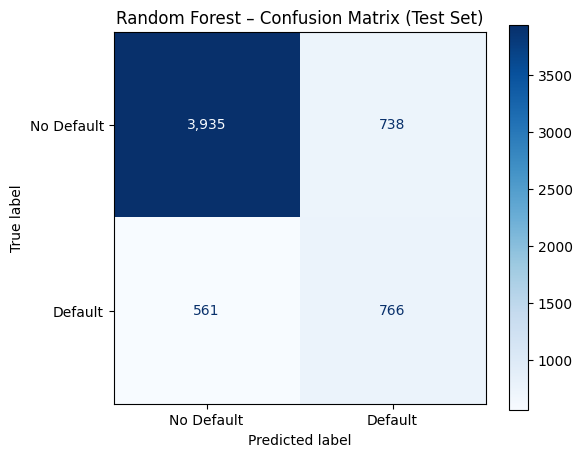

In [8]:
# ===== Confusion matrix =====
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues", values_format=",", ax=ax)
ax.set_title("Random Forest – Confusion Matrix (Test Set)")
plt.savefig(PLOTS_DIR / "rf_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:**

- **True Negatives (3,935):** non-defaulters correctly identified.
- **True Positives (766):** defaulters correctly caught.
- **False Positives (738):** good clients wrongly flagged as risky. The cost is a lost customer or an unnecessary review.
- **False Negatives (561):** defaulters the model missed. This is the **most costly error for the bank**, because the bank keeps lending to a client who will not pay.

Out of 1,327 actual defaulters in the test set, the model missed 561. Reducing this number is the main goal of the threshold analysis in Section 9.

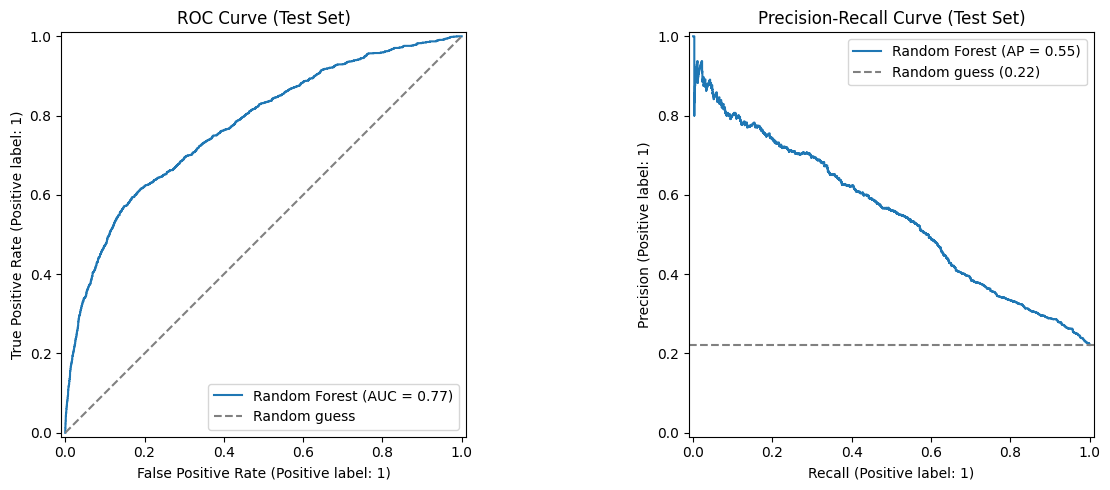

In [9]:
# ===== ROC and Precision-Recall curves =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(y_test, y_proba, name="Random Forest", ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[0].set_title("ROC Curve (Test Set)")
axes[0].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_proba, name="Random Forest", ax=axes[1])
axes[1].axhline(y_test.mean(), linestyle="--", color="gray",
                label=f"Random guess ({y_test.mean():.2f})")
axes[1].set_title("Precision-Recall Curve (Test Set)")
axes[1].legend()

plt.tight_layout()
plt.savefig(PLOTS_DIR / "rf_roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:**

- **ROC curve (left):** The curve stays well above the diagonal (random guessing), with AUC = 0.773. The model separates defaulters from non-defaulters much better than chance.
- **Precision-Recall curve (right):** This curve is more informative for imbalanced data because it focuses on the Default class. The random-guess line is at 0.22 (the share of defaulters). The model's average precision is 0.55, which is 2.5 times higher than random guessing. The curve also shows the trade-off: to catch more defaulters (higher recall), we must accept more false alarms (lower precision).

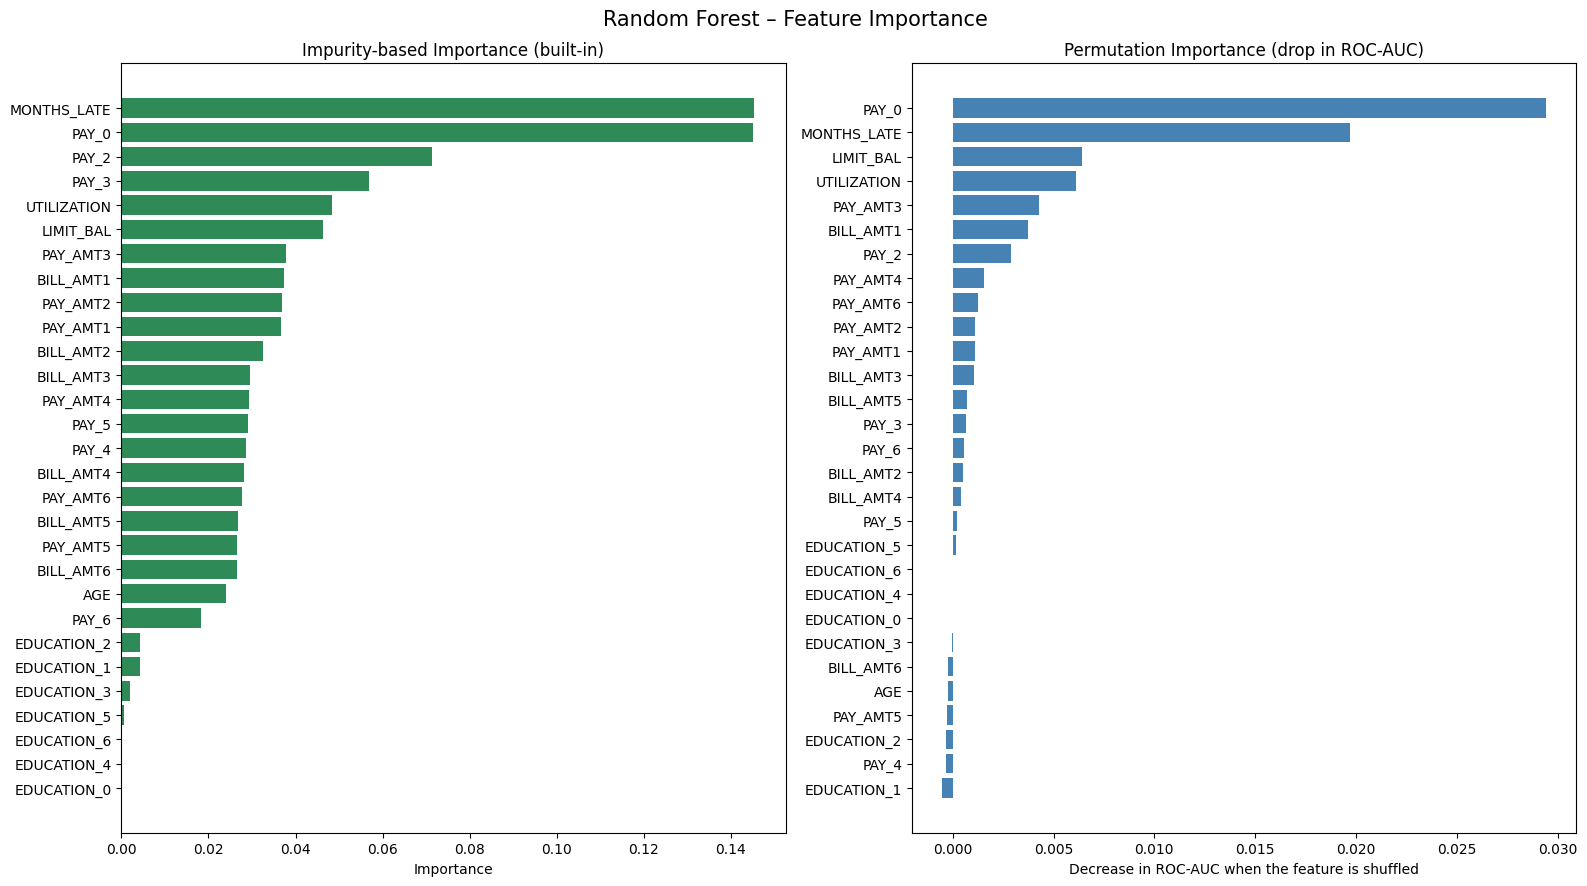

,Impurity rank,Permutation rank
PAY_0,2,1
MONTHS_LATE,1,2
LIMIT_BAL,6,3
UTILIZATION,5,4
PAY_AMT3,7,5
BILL_AMT1,8,6
PAY_2,3,7
PAY_AMT4,13,8
PAY_AMT6,17,9
PAY_AMT2,9,10


In [10]:
# ===== Feature importance: built-in vs permutation =====
impurity_imp = pd.Series(best_rf.feature_importances_,
                         index=X_train.columns).sort_values()

# Permutation importance: shuffle one feature and measure the drop in ROC-AUC
perm = permutation_importance(best_rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_train.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
axes[0].barh(impurity_imp.index, impurity_imp.values, color="seagreen")
axes[0].set_title("Impurity-based Importance (built-in)")
axes[0].set_xlabel("Importance")
axes[1].barh(perm_imp.index, perm_imp.values, color="steelblue")
axes[1].set_title("Permutation Importance (drop in ROC-AUC)")
axes[1].set_xlabel("Decrease in ROC-AUC when the feature is shuffled")
plt.suptitle("Random Forest – Feature Importance", fontsize=15)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

# Rank comparison (1 = most important)
rank_table = pd.DataFrame({
    "Impurity rank": impurity_imp.rank(ascending=False).astype(int),
    "Permutation rank": perm_imp.rank(ascending=False).astype(int),
}).sort_values("Permutation rank")
rank_table.head(10)

## 7. Feature Importance

**Interpretation:**

We compared two importance methods:
- **Impurity-based importance** (built into Random Forest) measures how much each feature is used to split the trees.
- **Permutation importance** shuffles one feature at a time on the test set and measures how much ROC-AUC drops. It shows how much the model really depends on the feature for correct predictions.

**Findings:**
- **PAY_0 and MONTHS_LATE** are the two most important features in both methods. This agrees with the EDA, where the default rate rose from 12.8% (PAY_0 = 0) to 69.4% (PAY_0 = 2), and from 11.5% (no late months) to 69.7% (late every month).
- **AGE** ranked second in the preliminary Random Forest in the Data Exploration notebook (Section 4.8), which used default settings. In our tuned model, it drops to 21st in impurity importance, and its permutation importance is close to zero (slightly negative), meaning that shuffling age does not hurt the model at all. This confirms the earlier observation: AGE has little real predictive value, and its high rank came from deep, unrestricted trees that split on features with many unique values. Limiting `max_depth` and `min_samples_leaf` reduced this bias.
- **PAY_2 and PAY_3** rank 3rd and 4th in impurity importance but much lower in permutation importance (7th and 14th). Because they are strongly correlated with PAY_0 and MONTHS_LATE, the model can rely on those features instead when PAY_2 or PAY_3 is shuffled.
- **The engineered features are useful:** MONTHS_LATE (1st / 2nd) and UTILIZATION (5th / 4th), both created in the preprocessing step, are among the top features in both methods.
- **EDUCATION** categories have almost no importance in either method.

**For decision-makers:** the model mainly relies on recent repayment behavior and credit usage, which is easy to explain to a credit manager.

In [11]:
# ===== Misclassification analysis =====
# Link test predictions back to the raw (unscaled) values using ID,
# so the numbers are easy to read
raw = pd.read_csv(ROOT / "Dataset" / "raw_kaggle_data.csv")

results = pd.DataFrame({"ID": test_ids.values, "y_true": y_test.values,
                        "y_pred": y_pred, "y_proba": y_proba})
results = results.merge(raw.drop(columns=[TARGET]), on="ID", how="left")

def outcome(row):
    if row.y_true == 1 and row.y_pred == 1:
        return "True Positive (caught default)"
    if row.y_true == 1 and row.y_pred == 0:
        return "False Negative (missed default)"
    if row.y_true == 0 and row.y_pred == 1:
        return "False Positive (false alarm)"
    return "True Negative"

results["outcome"] = results.apply(outcome, axis=1)
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
results["MONTHS_LATE"] = (results[pay_cols] > 0).sum(axis=1)

key_features = ["PAY_0", "MONTHS_LATE", "LIMIT_BAL", "PAY_AMT1", "BILL_AMT1"]
display(results.groupby("outcome")[key_features].median().round(1))

missed = results[results["outcome"].str.startswith("False Negative")]
caught = results[results["outcome"].str.startswith("True Positive")]
print(f"Missed defaulters with no recent delay (PAY_0 <= 0): "
      f"{(missed['PAY_0'] <= 0).mean() * 100:.1f}%")
print(f"Caught defaulters with no recent delay (PAY_0 <= 0): "
      f"{(caught['PAY_0'] <= 0).mean() * 100:.1f}%")

,PAY_0,MONTHS_LATE,LIMIT_BAL,PAY_AMT1,BILL_AMT1
outcome,,,,,
False Negative (missed default),0.0,0.0,140000.0,2000.0,14853.0
False Positive (false alarm),1.0,2.0,70000.0,780.0,17803.0
True Negative,0.0,0.0,170000.0,2880.0,25079.0
True Positive (caught default),2.0,3.0,80000.0,1303.0,22526.5


Missed defaulters with no recent delay (PAY_0 <= 0): 93.6%
Caught defaulters with no recent delay (PAY_0 <= 0): 18.5%


## 8. Misclassification Analysis

We linked each test prediction to the original (unscaled) values using `ID` and compared the clients the model missed (False Negatives) with the ones it caught (True Positives).

**Pattern:** 93.6% of the missed defaulters had **no payment delay in the most recent month** (PAY_0 ≤ 0), compared with only 18.5% of the caught defaulters. Their median number of late months is 0, versus 3 for caught defaulters.

**Challenging category:** clients who look healthy in their recent repayment history but still default. Their payment records look like those of good clients, so the model has very little signal to detect them. This is a limitation of the available features, not only of the model.

In [12]:
# ===== Decision threshold analysis =====
# Out-of-fold probabilities on the TRAINING set
# (the threshold is chosen without looking at the test set)
oof_proba = cross_val_predict(best_rf, X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]

rows = []
for t in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pred = (oof_proba >= t).astype(int)
    rows.append({"Threshold": t,
                 "Precision": precision_score(y_train, pred),
                 "Recall": recall_score(y_train, pred),
                 "F1": f1_score(y_train, pred)})
threshold_table = pd.DataFrame(rows)
display(threshold_table.round(3))

best_threshold = threshold_table.loc[threshold_table["F1"].idxmax(), "Threshold"]
print("Threshold with the best F1 on training folds:", best_threshold)

# Report the test results for the default, the best-F1 and a high-recall threshold
thresholds_to_report = sorted({0.40, float(best_threshold), 0.50})
threshold_compare = pd.DataFrame({
    f"Threshold {t:.2f}": [precision_score(y_test, (y_proba >= t).astype(int)),
                           recall_score(y_test, (y_proba >= t).astype(int)),
                           f1_score(y_test, (y_proba >= t).astype(int))]
    for t in thresholds_to_report
}, index=["Precision", "Recall", "F1"])
threshold_compare.round(3)

,Threshold,Precision,Recall,F1
0,0.30,0.326,0.847,0.471
1,0.35,0.370,0.767,0.500
2,0.40,0.423,0.687,0.523
3,0.45,0.472,0.629,0.539
4,0.50,0.512,0.580,0.544
5,0.55,0.549,0.539,0.544
6,0.60,0.581,0.500,0.538


Threshold with the best F1 on training folds: 0.5


,Threshold 0.40,Threshold 0.50
Precision,0.412,0.509
Recall,0.662,0.577
F1,0.508,0.541


## 9. Decision Threshold Analysis

By default, a client is classified as "Default" when the predicted probability is at least 0.5. For a bank, missing a defaulter usually costs more than reviewing a good client, so a lower threshold can be more useful.

We chose the threshold using **out-of-fold predictions on the training set**, not the test set, to avoid data leakage.

**Result:** The threshold with the best F1 on the training folds is 0.50. This is because `class_weight="balanced"` already gives the Default class more weight, so the model's probabilities are shifted toward Default. On the test set, lowering the threshold to 0.40 increases recall from 0.577 to 0.662, while precision drops from 0.509 to 0.412.

**Business meaning:** A bank that wants to catch more defaulters can lower the threshold and accept more manual reviews. The right threshold depends on the cost of each error type, which is a decision for management. This flexibility is useful for the executive dashboard in Phase 2 (for example, a threshold slider).

In [13]:
# ===== Save the model and results for the team =====
model_path = MODELS_DIR / "rf_model.joblib"
joblib.dump(best_rf, model_path, compress=3)   # compressed to keep the file small
model_mb = model_path.stat().st_size / 1e6
print(f"Model size: {model_mb:.1f} MB  (GitHub limit: 100 MB)")

test_metrics["model_size_mb"] = model_mb
test_metrics["tuned_threshold"] = float(best_threshold)
with open(RESULTS_DIR / "rf_test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

# Predictions for the comparison with SVM (Member 7)
pd.DataFrame({"ID": test_ids.values, "y_true": y_test.values,
              "y_pred": y_pred, "y_proba": y_proba}
             ).to_csv(RESULTS_DIR / "rf_test_predictions.csv", index=False)

print(f"Training time of the final model: {test_metrics['train_time_seconds']:.1f} s")
print("Saved results:", sorted(p.name for p in RESULTS_DIR.glob("rf_*")))
print("Saved plots:  ", sorted(p.name for p in PLOTS_DIR.glob("rf_*")))

Model size: 3.4 MB  (GitHub limit: 100 MB)
Training time of the final model: 4.3 s
Saved results: ['rf_best_params.json', 'rf_cv_results.csv', 'rf_test_metrics.json', 'rf_test_predictions.csv']
Saved plots:   ['rf_confusion_matrix.png', 'rf_feature_importance.png', 'rf_roc_pr_curves.png']


## 10. Random Forest Summary

| Item | Value |
|---|---|
| Best parameters | n_estimators=100, max_depth=12, min_samples_split=5, min_samples_leaf=8, max_features="log2", class_weight="balanced" |
| Test F1 (Default class) | 0.541 |
| Test Recall (Default class) | 0.577 |
| Test ROC-AUC | 0.773 |
| Training time | 10.4 seconds |
| Model size | 3.4 MB |

**Trade-offs:**
- **Accuracy:** After tuning, the model catches 58% of defaulters (compared with 38% before tuning) with stable results across cross-validation and the test set, but about half of the clients it flags as risky do not actually default (precision 0.509).
- **Interpretability:** Feature importance gives a clear ranking of risk drivers, but the model is an ensemble of many trees, so individual decisions are harder to explain than with a single tree.
- **Computational cost:** Training takes 10.4 seconds and the model file is 3.4 MB, which is acceptable for a bank's batch risk scoring.

The saved predictions (`rf_test_predictions.csv`) and metrics (`rf_test_metrics.json`) are used in the model comparison section.